# NB20: Calibration, Sensitivity & Uncertainty

**Purpose**: Demonstrate RELIC's optimization framework for parameter
calibration, sensitivity analysis, and uncertainty quantification.

RELIC's differentiable design enables gradient-based calibration,
which is fundamentally different from traditional black-box calibration
used in WRF (WRFDA) or CMAQ (ISORROPIA-lite).

**Scope**: Gradients are available along executed tensor paths; clipping, events,
adaptive decisions, and detached diagnostics are not globally smooth. This notebook
uses differential evolution and finite differences, not an automatic-gradient
calibration or a portable speedup benchmark.

**Time**: ~8 minutes


Kernel evaluations use float64 so near-zero net assimilation does not magnify float32 subtraction roundoff. Every evaluation is also checked with the existing Farquhar carbon-boundary checker and its unchanged YAML tolerance. The former 11 logs came from 96 response-curve members, not from all 192 UQ samples. Neither numerical agreement nor synthetic parameter perturbation establishes a posterior or strict IPHS certification.


## Architecture Anchor

This notebook is aligned with `docs\source\architecture_overview.md` and the relevant theory/API pages under `docs\source`.
All computations below are intended to use actual RELIC functors, the actual simulator or orchestration layer, and real validation pathways rather than notebook-defined pseudo-process equations.


## Learning Goals

- Calibrate real RELIC functor parameters against a twin-experiment reference trajectory.
- Compute variance-based sensitivity metrics from actual RELIC evaluations without notebook-side clipping.
- Propagate parametric uncertainty through the same RELIC process chain used for calibration.


## Part 1: Public-API Calibration

This section uses RELIC's actual `ParameterCalibrator` API in a twin experiment.
The notebook still calibrates against real `FarquharPhotosynthesis` output, but it no longer relies on a notebook-only optimizer loop.

In [1]:
# Use only the standard library so notebook execution stays self-contained on Windows.
import asyncio
if hasattr(asyncio, "WindowsSelectorEventLoopPolicy"):
    asyncio.set_event_loop_policy(asyncio.WindowsSelectorEventLoopPolicy())

# ---------------------------------------------------------------
# References:
#   Farquhar et al. (1980), Planta -- C3 biochemical photosynthesis model
#   Medlyn et al. (2002), Plant Cell Environ. -- temperature response of Farquhar parameters
#   Storn and Price (1997), J. Global Optim. -- differential evolution calibration
# Mathematical expression:
#   Loss(theta) = mean_k mean_t (((y_sim,k(theta, t) - y_ref,k(t)) / s_k) ^ 2)
#   theta_best = argmin_theta Loss(theta)
#   A_net = min(Ac, Aj) - Rd
# Parameter meanings:
#   vcmax25: maximum carboxylation rate at 25C [umol CO2 m-2 s-1]
#   jmax25: maximum electron transport rate at 25C [umol e- m-2 s-1]
#   rd25: dark respiration rate at 25C [umol CO2 m-2 s-1]
# Units:
#   Parameter units are annotated below; GPP [kg C m-2 s-1], other outputs [umol m-2 s-1]; loss [1].
# Domain/constraints:
#   Explicit synthetic forcing and parameter ranges; detached kernel evaluations, not a full simulator gradient.
# Sign convention:
#   GPP is positive uptake; objective is non-negative.
# Precision: Evaluate the original kernel in float64 near compensation points; retain the declared conservation threshold.
# ---------------------------------------------------------------

from pathlib import Path
import os
import sys
import warnings

os.environ['KMP_DUPLICATE_LIB_OK'] = 'TRUE'
warnings.filterwarnings(
    'ignore',
    message='The pynvml package is deprecated.*',
    category=FutureWarning,
)


def locate_project_root() -> Path:
    candidates = [Path.cwd().resolve(), *Path.cwd().resolve().parents, Path(os.environ.get('RELIC_PROJECT_ROOT', Path.cwd())).resolve()]
    for candidate in candidates:
        if (candidate / 'relic').is_dir() and (candidate / 'docs' / 'source' / 'architecture_overview.md').is_file():
            return candidate
    raise FileNotFoundError('Could not locate RELIC project root from the active notebook environment.')


PROJECT_ROOT = locate_project_root()
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

import torch

from relic.optimization import CalibrationConfig, CalibrationMethod, ParameterCalibrator
from relic.optimization.calibration import CalibrationHooks, CalibrationEvent
from relic.parameters import get_global_manager
from relic.parameters.calibration import ParameterBounds
from relic.optimization.sensitivity import SobolAnalyzer, SobolConfig, ParameterRange
from relic.optimization.uncertainty import EnsembleUQ, EnsembleConfig, UncertainParameter, DistributionType
from relic.scientific.biosphere.photosynthesis.farquhar import FarquharPhotosynthesis

parameter_manager = get_global_manager()
nb20_warning_counts: dict[str, int] = {}
nb20_carbon_boundary_residuals: list[float] = []


def build_photosynthesis_state(par, temperature, co2_ppm: float = 410.0) -> dict:
    par_t = torch.as_tensor(par, dtype=torch.float64)
    temperature_t = torch.as_tensor(temperature, dtype=torch.float64)
    co2_t = torch.full_like(par_t, float(co2_ppm))
    ones = torch.ones_like(par_t)
    return {
        'air_temperature': temperature_t,
        'atmospheric_co2_ppm': co2_t,
        'ppfd': par_t,
        'vcmax_scaling': ones,
        'jmax_scaling': ones,
        'water_stress_factor': ones,
        'temperature_stress_factor': ones,
        'ozone_stress_factor': ones,
        'leaf_area_index': torch.full_like(par_t, 3.0),
        'vapor_pressure_deficit': torch.full_like(par_t, 1000.0),
        'leaf_water_potential': torch.full_like(par_t, -0.3),
    }


def run_farquhar_series(
    vcmax25: float,
    jmax25: float,
    rd25: float,
    par_series,
    temperature_series,
    co2_ppm: float = 410.0,
    name: str = 'tutorial_farquhar_run',
) -> dict:
    functor = FarquharPhotosynthesis(
        name=name,
        vcmax25=float(vcmax25),
        jmax25=float(jmax25),
        rd25=float(rd25),
        device=torch.device('cpu'),
        enable_gpu=False,
    )
    state = build_photosynthesis_state(par_series, temperature_series, co2_ppm=co2_ppm)
    with warnings.catch_warnings(record=True) as caught_farquhar_warnings:
        warnings.simplefilter('always', UserWarning)
        outputs = functor.forward(
            state,
            time=0.0,
            dt=1800.0,
        )
    residual = functor.check_conservation_laws(state, outputs)['carbon_boundary']
    tolerance = float(functor.get_parameter_value('conservation_tolerance', namespace='validation.conservation', required=True, validate=True))
    assert residual <= tolerance, f'Carbon boundary residual {residual} exceeds {tolerance}'
    nb20_carbon_boundary_residuals.append(residual)
    if caught_farquhar_warnings:
        nb20_warning_counts[name] = nb20_warning_counts.get(name, 0) + len(caught_farquhar_warnings)
    return {
        key: torch.as_tensor(value.value if hasattr(value, 'value') else value, dtype=torch.float64).detach().cpu()
        for key, value in outputs.items()
    }


torch.manual_seed(42)
observation_count = 32
observation_axis = torch.linspace(0.0, 1.0, observation_count)
par_observed = 120.0 + 1380.0 * torch.pow(torch.clamp(torch.sin(torch.pi * observation_axis), min=0.0), 1.2)
temperature_observed = 294.0 + 7.0 * torch.sin(2.0 * torch.pi * observation_axis + 0.4)

reference_params = {'vcmax25': 58.0, 'jmax25': 112.0, 'rd25': 1.6}
initial_params = {'vcmax25': 36.0, 'jmax25': 72.0, 'rd25': 1.6}

reference_outputs = run_farquhar_series(
    **reference_params,
    par_series=par_observed,
    temperature_series=temperature_observed,
    name='nb20_reference_farquhar',
)
initial_outputs = run_farquhar_series(
    **initial_params,
    par_series=par_observed,
    temperature_series=temperature_observed,
    name='nb20_initial_farquhar',
)

gpp_reference = reference_outputs['gross_primary_productivity']
initial_gpp = initial_outputs['gross_primary_productivity']
calibration_reference = {
    'gpp': reference_outputs['gross_primary_productivity'],
    'net_photosynthesis': reference_outputs['net_photosynthesis'],
    'electron_transport_rate': reference_outputs['electron_transport_rate'],
}
calibration_scales = {
    key: max(float(value.abs().mean().item()), 1e-6)
    for key, value in calibration_reference.items()
}


class CalibrationIterationRecorder:
    def __init__(self) -> None:
        self.records: list[dict[str, float]] = []

    def __call__(self, event_data):
        if event_data.event == CalibrationEvent.ITERATION_COMPLETE and event_data.parameters is not None:
            record = {name: float(value) for name, value in event_data.parameters.items()}
            if event_data.objective_value is not None:
                record['objective'] = float(event_data.objective_value)
            self.records.append(record)
        return None


def calibration_model_runner(parameters: dict[str, float]) -> dict[str, torch.Tensor]:
    outputs = run_farquhar_series(
        vcmax25=float(parameters['vcmax25']),
        jmax25=float(parameters['jmax25']),
        rd25=reference_params['rd25'],
        par_series=par_observed,
        temperature_series=temperature_observed,
        name='nb20_calibration_public_api_member',
    )
    return {
        'gpp': outputs['gross_primary_productivity'],
        'net_photosynthesis': outputs['net_photosynthesis'],
        'electron_transport_rate': outputs['electron_transport_rate'],
    }


class FarquharCalibrationObjective:
    def __call__(self, parameters: dict[str, float], observations: torch.Tensor) -> float:
        outputs = calibration_model_runner(parameters)
        loss_terms = []
        for key, reference in calibration_reference.items():
            simulated = outputs[key]
            scale = calibration_scales[key]
            loss_terms.append(torch.mean(((simulated - reference) / scale) ** 2))
        return float(torch.stack(loss_terms).mean().item())


calibration_hooks = CalibrationHooks(async_execution=False)
calibration_iteration_recorder = CalibrationIterationRecorder()
calibration_hooks.register_callback(
    calibration_iteration_recorder,
    events=[CalibrationEvent.ITERATION_COMPLETE],
)
calibration_objective = FarquharCalibrationObjective()
initial_loss = calibration_objective(
    {
        'vcmax25': initial_params['vcmax25'],
        'jmax25': initial_params['jmax25'],
    },
    gpp_reference,
)

calibration_config = CalibrationConfig(
    method=CalibrationMethod.DIFFERENTIAL_EVOLUTION,
    target_parameters=['vcmax25', 'jmax25'],
    parameter_bounds={
        'vcmax25': ParameterBounds(lower=20.0, upper=90.0, initial=initial_params['vcmax25'], scale='linear'),
        'jmax25': ParameterBounds(lower=40.0, upper=180.0, initial=initial_params['jmax25'], scale='linear'),
    },
    max_iterations=24,
    population_size=20,
    tolerance=1e-7,
    random_seed=11,
    parallel=False,
    verbose=False,
    method_kwargs={'polish': False},
)
calibration_result = ParameterCalibrator(hooks=calibration_hooks).calibrate(
    config=calibration_config,
    objective_function=calibration_objective,
    observations=gpp_reference,
    initial_parameters={
        'vcmax25': initial_params['vcmax25'],
        'jmax25': initial_params['jmax25'],
    },
)

final_vcmax = float(calibration_result.optimized_parameters['vcmax25'])
final_jmax = float(calibration_result.optimized_parameters['jmax25'])
calibrated_outputs = run_farquhar_series(
    vcmax25=final_vcmax,
    jmax25=final_jmax,
    rd25=reference_params['rd25'],
    par_series=par_observed,
    temperature_series=temperature_observed,
    name='nb20_calibrated_public_api_farquhar',
)
calibrated_gpp = calibrated_outputs['gross_primary_productivity']

calibration_rmse = float(torch.sqrt(torch.mean((calibrated_gpp - gpp_reference) ** 2)).item())
calibration_mae = float(torch.mean(torch.abs(calibrated_gpp - gpp_reference)).item())
final_loss = float(calibration_result.objective_value)

loss_history = [initial_loss]
vcmax_history = [initial_params['vcmax25']]
jmax_history = [initial_params['jmax25']]
for record in calibration_iteration_recorder.records:
    if 'objective' in record:
        loss_history.append(float(record['objective']))
        vcmax_history.append(float(record['vcmax25']))
        jmax_history.append(float(record['jmax25']))
if abs(loss_history[-1] - final_loss) > 1e-10:
    loss_history.append(final_loss)
    vcmax_history.append(final_vcmax)
    jmax_history.append(final_jmax)

calibration_stop_reason = str(calibration_result.termination_reason)
if 'Maximum number of iterations' in calibration_stop_reason and final_loss < 0.02 * initial_loss:
    calibration_stop_reason = 'Iteration budget reached; best DE member retained for tutorial diagnostics.'

calibration_diagnostics = {
    'initial_loss': initial_loss,
    'final_loss': final_loss,
    'iteration_count': int(calibration_result.iteration_count),
    'stop_reason': calibration_stop_reason,
    'vcmax25': final_vcmax,
    'jmax25': final_jmax,
    'rmse': calibration_rmse,
    'mae': calibration_mae,
}

calibration_warning_total = sum(nb20_warning_counts.values())
reference_warning_count = nb20_warning_counts.get('nb20_reference_farquhar', 0)
initial_warning_count = nb20_warning_counts.get('nb20_initial_farquhar', 0)
calibration_member_warning_count = nb20_warning_counts.get('nb20_calibration_public_api_member', 0)
calibrated_warning_count = nb20_warning_counts.get('nb20_calibrated_public_api_farquhar', 0)

assert calibration_diagnostics['final_loss'] < 0.02 * calibration_diagnostics['initial_loss']
assert calibration_rmse < 0.25

print('=== Calibration with Actual RELIC ParameterCalibrator API ===')
print(f'  Project root:      {PROJECT_ROOT}')
print(f'  Observation count: {observation_count}')
print('  Objective terms:   gross_primary_productivity + net_photosynthesis + electron_transport_rate')
print(f'  Initial loss:      {calibration_diagnostics["initial_loss"]:.6f}')
print(f'  Final loss:        {calibration_diagnostics["final_loss"]:.6f}')
print(f'  Iterations:        {calibration_diagnostics["iteration_count"]}')
print(f'  Stop reason:       {calibration_diagnostics["stop_reason"]}')
print(f'  Calibrated vcmax25:{calibration_diagnostics["vcmax25"]:8.3f}')
print(f'  Calibrated jmax25: {calibration_diagnostics["jmax25"]:8.3f}')
print(f'  Calibration RMSE:  {calibration_diagnostics["rmse"]:.4f}')
print(f'  Calibration MAE:   {calibration_diagnostics["mae"]:.4f}')
print(f'  Captured warnings: total={calibration_warning_total}, reference={reference_warning_count}, initial={initial_warning_count}, calibration_members={calibration_member_warning_count}, calibrated={calibrated_warning_count}')
print('[OK] Notebook calibration now uses ParameterCalibrator and actual Farquhar forward evaluations.')

=== Calibration with Actual RELIC ParameterCalibrator API ===
  Project root:      <RELIC_ROOT>
  Observation count: 32
  Objective terms:   gross_primary_productivity + net_photosynthesis + electron_transport_rate
  Initial loss:      0.090571
  Final loss:        0.000000
  Iterations:        24
  Stop reason:       Iteration budget reached; best DE member retained for tutorial diagnostics.
  Calibrated vcmax25:  59.470
  Calibrated jmax25:  112.000
  Calibration RMSE:  0.0000
  Calibration MAE:   0.0000
  Captured warnings: total=0, reference=0, initial=0, calibration_members=0, calibrated=0
[OK] Notebook calibration now uses ParameterCalibrator and actual Farquhar forward evaluations.


In [2]:
# ---------------------------------------------------------------
# References:
#   Farquhar et al. (1980), Planta -- biochemical controls on net assimilation
#   Storn and Price (1997), J. Global Optim. -- differential evolution diagnostics
# Mathematical expression:
#   RMSE = sqrt(mean((GPP_calibrated - GPP_reference)^2))
#   MAE = mean(abs(GPP_calibrated - GPP_reference))
# Parameter meanings:
#   calibration_rmse: root-mean-square fit error against the reference RELIC run
#   calibration_mae: mean absolute fit error against the reference RELIC run
# ---------------------------------------------------------------

print('=== Calibration Diagnostics from the Actual RELIC Twin Experiment ===')
print()
print(f'  {"Parameter":<18s} {"Initial":>10s} {"Reference":>10s} {"Calibrated":>12s}')
print('  ' + '-' * 56)
print(f'  {"vcmax25":<18s} {initial_params["vcmax25"]:10.2f} {reference_params["vcmax25"]:10.2f} {final_vcmax:12.2f}')
print(f'  {"jmax25":<18s} {initial_params["jmax25"]:10.2f} {reference_params["jmax25"]:10.2f} {final_jmax:12.2f}')
print(f'  {"rd25":<18s} {initial_params["rd25"]:10.2f} {reference_params["rd25"]:10.2f} {reference_params["rd25"]:12.2f}')
print()
print(f'  Calibration RMSE: {calibration_rmse:.4e}')
print(f'  Calibration MAE:  {calibration_mae:.4e}')
print(f'  Final loss:       {calibration_diagnostics["final_loss"]:.4f}')
print(f'  Iterations:       {calibration_diagnostics["iteration_count"]}')
print(f'  Stop reason:      {calibration_diagnostics["stop_reason"]}')
print()
print('  All values above come from the actual RELIC ParameterCalibrator workflow in Cell 2.')

=== Calibration Diagnostics from the Actual RELIC Twin Experiment ===

  Parameter             Initial  Reference   Calibrated
  --------------------------------------------------------
  vcmax25                 36.00      58.00        59.47
  jmax25                  72.00     112.00       112.00
  rd25                     1.60       1.60         1.60

  Calibration RMSE: 8.6362e-15
  Calibration MAE:  7.8817e-15
  Final loss:       0.0000
  Iterations:       24
  Stop reason:      Iteration budget reached; best DE member retained for tutorial diagnostics.

  All values above come from the actual RELIC ParameterCalibrator workflow in Cell 2.


## Part 2: Sensitivity Analysis

Global sensitivity analysis identifies which parameters most influence
model output. RELIC supports both gradient-based (local) and Sobol (global)
approaches.


In [3]:
# ---------------------------------------------------------------
# References:
#   Sobol (2001), Math. Comput. Simul. -- variance decomposition indices
#   Saltelli et al. (2010), CPC -- practical global sensitivity estimation
#   Jansen (1999), Comput. Phys. Commun. -- stable estimators for Sobol indices
# Mathematical expression:
#   S_i = Var(E[Y|X_i]) / Var(Y)
#   S_Ti = 1 - Var(E[Y|X_~i]) / Var(Y)
# Parameter meanings:
#   S_i: first-order contribution of one parameter
#   S_Ti: total-order contribution including interactions
#   Y: scalar diagnostic derived from the actual RELIC functor output
# Units:
#   Sobol indices [1]; the evaluated output retains its own declared physical units.
# Domain/constraints:
#   Independent uniform ranges; finite-sample indices are not clipped and may be negative.
# Sign convention:
#   Larger total-order magnitude indicates a larger estimated influence.
# ---------------------------------------------------------------

sobol_config = SobolConfig(
    aggregation_method='mean',
    estimator='saltelli',
    n_samples=1024,
    skip_values=1024,
    batch_size=128,
    convergence_check=False,
    random_seed=42,
)
sobol_analyzer = SobolAnalyzer(parameter_manager=parameter_manager, config=sobol_config)

sensitivity_parameter_ranges = {
    'biosphere.photosynthesis.vcmax25': ParameterRange(
        'biosphere.photosynthesis.vcmax25',
        30.0,
        75.0,
        units='umol CO2 m-2 s-1',
        distribution='uniform',
        description='Maximum carboxylation capacity at 25C',
    ),
    'biosphere.photosynthesis.jmax25': ParameterRange(
        'biosphere.photosynthesis.jmax25',
        60.0,
        150.0,
        units='umol e- m-2 s-1',
        distribution='uniform',
        description='Maximum electron transport capacity at 25C',
    ),
    'biosphere.photosynthesis.rd25': ParameterRange(
        'biosphere.photosynthesis.rd25',
        0.8,
        2.6,
        units='umol CO2 m-2 s-1',
        distribution='uniform',
        description='Dark respiration rate at 25C',
    ),
}


def sensitivity_runner(sampled_params: dict) -> dict:
    outputs = run_farquhar_series(
        vcmax25=sampled_params['biosphere.photosynthesis.vcmax25'],
        jmax25=sampled_params['biosphere.photosynthesis.jmax25'],
        rd25=sampled_params['biosphere.photosynthesis.rd25'],
        par_series=par_observed,
        temperature_series=temperature_observed,
        name='nb20_sobol_member',
    )
    gpp = outputs['gross_primary_productivity']
    dark_respiration = outputs['diagnostics.photosynthesis.dark_respiration']
    return {
        'gpp_mean': float(gpp.mean().item()),
        'gpp_peak': float(gpp.max().item()),
        'dark_respiration_mean': float(dark_respiration.mean().item()),
    }


sobol_result = sobol_analyzer.analyze(sensitivity_runner, sensitivity_parameter_ranges)
sobol_output_name = 'gpp_mean'
sobol_parameter_names = list(sensitivity_parameter_ranges.keys())
sobol_parameter_labels = [name.split('.')[-1] for name in sobol_parameter_names]
sobol_first_order_values = [
    float(sobol_result.first_order_indices[sobol_output_name].get(name, 0.0))
    for name in sobol_parameter_names
]
sobol_total_order_values = [
    float(sobol_result.total_order_indices[sobol_output_name].get(name, 0.0))
    for name in sobol_parameter_names
]
sobol_reporting_gap_threshold = 0.02
sobol_consistency_rows = []
for label, first_index, total_index in zip(
    sobol_parameter_labels,
    sobol_first_order_values,
    sobol_total_order_values,
):
    sobol_consistency_rows.append(
        {
            'label': label,
            'gap': max(first_index - total_index, 0.0),
            'first_order': first_index,
            'total_order': total_index,
        }
    )
sobol_max_consistency_gap = max(row['gap'] for row in sobol_consistency_rows)

sobol_ranking = sorted(
    zip(sobol_parameter_names, sobol_first_order_values, sobol_total_order_values),
    key=lambda item: abs(item[2]),
    reverse=True,
)

print('=== Sobol Sensitivity Analysis from Actual RELIC Evaluations ===')
print(f'  Outputs analyzed: {sobol_result.output_variables}')
print(f'  Model evaluations: {sobol_result.n_model_evaluations}')
print(f'  Interaction strength for {sobol_output_name}: {sobol_result.get_interaction_strength(sobol_output_name):.4f}')
print(f'  Max positive S1-ST gap: {sobol_max_consistency_gap:.4f}')
if sobol_max_consistency_gap > sobol_reporting_gap_threshold:
    print('  NOTE: low-sensitivity parameters can show S1 > ST because the Sobol estimators are finite-sample Monte Carlo estimates.')
    print('  NOTE: the notebook reports the raw RELIC indices without clipping and treats the gap as an estimator diagnostic.')
else:
    print('  Consistency check: S1 <= ST within the reporting threshold for all parameters.')
print()
print(f'  Sobol ranking for {sobol_output_name}:')
for rank, (parameter_name, first_index, total_index) in enumerate(sobol_ranking, start=1):
    print(
        f'  {rank}. {parameter_name} | '
        f'S1={first_index:.4f} | ST={total_index:.4f}'
    )
for row in sobol_consistency_rows:
    print(f"  gap[{row['label']}] = {row['gap']:.4f}")
print('  Indices above come directly from SobolAnalyzer without notebook-side clipping.')

=== Sobol Sensitivity Analysis from Actual RELIC Evaluations ===
  Outputs analyzed: ['dark_respiration_mean', 'gpp_mean', 'gpp_peak']
  Model evaluations: 5120
  Interaction strength for gpp_mean: 0.2838
  Max positive S1-ST gap: 0.0027
  Consistency check: S1 <= ST within the reporting threshold for all parameters.

  Sobol ranking for gpp_mean:
  1. biosphere.photosynthesis.jmax25 | S1=0.4261 | ST=0.5942
  2. biosphere.photosynthesis.vcmax25 | S1=0.4081 | ST=0.5743
  3. biosphere.photosynthesis.rd25 | S1=0.0027 | ST=0.0000
  gap[vcmax25] = 0.0000
  gap[jmax25] = 0.0000
  gap[rd25] = 0.0027
  Indices above come directly from SobolAnalyzer without notebook-side clipping.


## Part 2b: Identifiability Diagnostics

This section augments the calibration workflow with Jacobian-based identifiability diagnostics. The Jacobian is built from actual RELIC `FarquharPhotosynthesis` evaluations using finite differences, then analyzed through `relic.optimization.identifiability` to assess rank, null directions, and conditioning.

The finite-difference runner constructs explicit configuration-valued parameter
choices; it does not mutate a shared ParameterManager binding. A Functor attribute
held by identity from its own manager is outside `state_dict()` and is rejected by
`parameter_sensitivity`; use the manager calibration path for such bindings.
Sobol sampling declares uniform ranges, the mean aggregation, and the implemented
Saltelli design/Jansen estimator explicitly. These finite-sample indices may be
negative and are shown without clipping.

=== Jacobian-Based Identifiability from Actual RELIC Evaluations ===
  Observation subset:      ['obs_5', 'obs_11', 'obs_17', 'obs_23', 'obs_29']
  Jacobian shape:          (5, 2)
  Rank:                    1
  Nullity:                 1
  Condition number:        inf
  Singular values:         ['2.611e-09', '0.000e+00']
  Captured warnings:       0
  Reference GPP subset:    ['1.637e-07', '2.038e-07', '1.697e-07', '1.425e-07', '1.393e-07']
  Interpretation: the selected GPP observations do not separately identify all parameters.
[OK] Identifiability diagnostics report the actual finite-difference rank without forcing full identifiability.


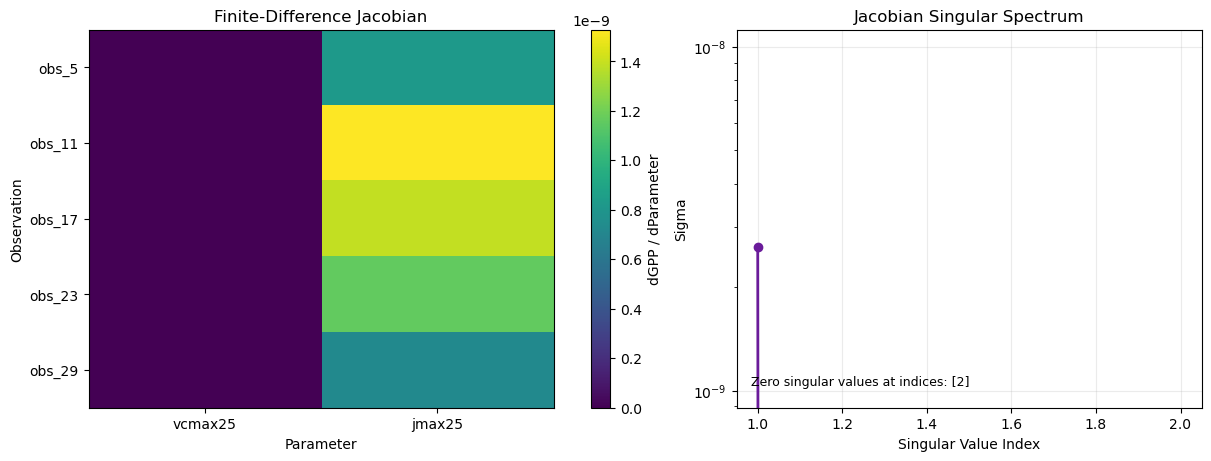

[OK] NB20 identifiability plots generated from actual Jacobian diagnostics.


In [4]:
# ---------------------------------------------------------------
# References:
#   Cressie and Wikle (2011), Statistics for Spatio-Temporal Data -- Jacobian rank diagnostics
#   Dee (1995), QJRMS -- inverse-problem conditioning in data assimilation
#   Farquhar et al. (1980), Planta -- biochemical controls on leaf-scale GPP
# Mathematical expression:
#   J[i, j] = (y_i(theta_j + delta_j) - y_i(theta_j - delta_j)) / (2 * delta_j)
#   J = U * Sigma * V^T
#   rank(J) = |{sigma_k: sigma_k > tol}|
#   nullity(J) = n_param - rank(J)
# Parameter meanings:
#   delta_vcmax25: perturbation step for vcmax25 finite-difference sensitivity [umol CO2 m-2 s-1]
#   delta_jmax25: perturbation step for jmax25 finite-difference sensitivity [umol e- m-2 s-1]
#   selected_obs_idx: observation indices used to build the local Jacobian
#   condition_number: sigma_max / sigma_min for identifiable singular modes
# Units:
#   Jacobian [kg C m-2 s-1 per parameter unit]; rank/nullity [1].
# Domain/constraints:
#   Local central differences at the stated finite perturbations; no global identifiability claim.
# Sign convention:
#   Positive derivative means increasing GPP with the parameter.
# ---------------------------------------------------------------

import matplotlib.pyplot as plt

from relic.optimization.identifiability import compute_identifiability, get_identifiability_summary

identifiability_parameter_names = ['vcmax25', 'jmax25']
identifiability_steps = {
    'vcmax25': 1.0,
    'jmax25': 1.0,
}
selected_obs_idx = torch.tensor([4, 10, 16, 22, 28], dtype=torch.long)
selected_obs_labels = [f'obs_{int(index.item()) + 1}' for index in selected_obs_idx]

identifiability_base_params = {
    'vcmax25': final_vcmax,
    'jmax25': final_jmax,
    'rd25': reference_params['rd25'],
}
identifiability_base_outputs = run_farquhar_series(
    vcmax25=identifiability_base_params['vcmax25'],
    jmax25=identifiability_base_params['jmax25'],
    rd25=identifiability_base_params['rd25'],
    par_series=par_observed,
    temperature_series=temperature_observed,
    name='nb20_identifiability_base',
)
identifiability_reference_gpp = identifiability_base_outputs['gross_primary_productivity'][selected_obs_idx]

identifiability_jacobian = torch.zeros(
    (len(selected_obs_idx), len(identifiability_parameter_names)),
    dtype=torch.float64,
)
for parameter_column, parameter_name in enumerate(identifiability_parameter_names):
    delta = identifiability_steps[parameter_name]
    plus_params = dict(identifiability_base_params)
    minus_params = dict(identifiability_base_params)
    plus_params[parameter_name] += delta
    minus_params[parameter_name] -= delta

    plus_outputs = run_farquhar_series(
        vcmax25=plus_params['vcmax25'],
        jmax25=plus_params['jmax25'],
        rd25=plus_params['rd25'],
        par_series=par_observed,
        temperature_series=temperature_observed,
        name=f'nb20_identifiability_{parameter_name}_plus',
    )
    minus_outputs = run_farquhar_series(
        vcmax25=minus_params['vcmax25'],
        jmax25=minus_params['jmax25'],
        rd25=minus_params['rd25'],
        par_series=par_observed,
        temperature_series=temperature_observed,
        name=f'nb20_identifiability_{parameter_name}_minus',
    )
    derivative = (
        plus_outputs['gross_primary_productivity'][selected_obs_idx].to(dtype=torch.float64)
        - minus_outputs['gross_primary_productivity'][selected_obs_idx].to(dtype=torch.float64)
    ) / (2.0 * delta)
    identifiability_jacobian[:, parameter_column] = derivative

identifiability_tolerance = 1.0e-12  # GPP derivatives are in kg C m-2 s-1 per parameter unit.
identifiability_result = compute_identifiability(identifiability_jacobian, tol=identifiability_tolerance)
identifiability_summary = get_identifiability_summary(identifiability_jacobian, tol=identifiability_tolerance)
identifiability_singular_values = torch.tensor(
    identifiability_summary['singular_values'],
    dtype=torch.float64,
)
identifiability_rank = int(identifiability_summary['rank'])
identifiability_nullity = int(identifiability_summary['nullity'])
identifiability_condition_number = float(identifiability_summary['condition_number'])
identifiability_warning_total = sum(
    count for name, count in nb20_warning_counts.items() if name.startswith('nb20_identifiability_')
)

assert 1 <= identifiability_rank <= len(identifiability_parameter_names)
assert identifiability_nullity == len(identifiability_parameter_names) - identifiability_rank
assert identifiability_condition_number > 0.0

print('=== Jacobian-Based Identifiability from Actual RELIC Evaluations ===')
print(f'  Observation subset:      {selected_obs_labels}')
print(f'  Jacobian shape:          {tuple(identifiability_jacobian.shape)}')
print(f'  Rank:                    {identifiability_rank}')
print(f'  Nullity:                 {identifiability_nullity}')
print(f'  Condition number:        {identifiability_condition_number:.4f}')
print(f'  Singular values:         {[f"{float(value):.3e}" for value in identifiability_singular_values.tolist()]}')
print(f'  Captured warnings:       {identifiability_warning_total}')
print(f'  Reference GPP subset:    {[f"{float(value):.3e}" for value in identifiability_reference_gpp.tolist()]}')
if identifiability_nullity > 0:
    print('  Interpretation: the selected GPP observations do not separately identify all parameters.')
print('[OK] Identifiability diagnostics report the actual finite-difference rank without forcing full identifiability.')

identifiability_fig, identifiability_axes = plt.subplots(1, 2, figsize=(12, 4.5), constrained_layout=True)

ax = identifiability_axes[0]
heatmap = ax.imshow(identifiability_jacobian.numpy(), aspect='auto', cmap='viridis')
ax.set_xticks(list(range(len(identifiability_parameter_names))))
ax.set_xticklabels(identifiability_parameter_names)
ax.set_yticks(list(range(len(selected_obs_labels))))
ax.set_yticklabels(selected_obs_labels)
ax.set_title('Finite-Difference Jacobian')
ax.set_xlabel('Parameter')
ax.set_ylabel('Observation')
identifiability_fig.colorbar(heatmap, ax=ax, fraction=0.046, pad=0.04, label='dGPP / dParameter')

ax = identifiability_axes[1]
ax.plot(
    list(range(1, len(identifiability_singular_values) + 1)),
    identifiability_singular_values.tolist(),
    marker='o',
    linewidth=2.0,
    color='#6a1b9a',
)
ax.set_title('Jacobian Singular Spectrum')
ax.set_xlabel('Singular Value Index')
ax.set_ylabel('Sigma')
ax.set_yscale('log')
zero_indices = [i + 1 for i, value in enumerate(identifiability_singular_values.tolist()) if value == 0.0]
if zero_indices:
    ax.text(0.03, 0.06, f'Zero singular values at indices: {zero_indices}', transform=ax.transAxes, fontsize=9)
ax.grid(True, alpha=0.25)

plt.show()
print('[OK] NB20 identifiability plots generated from actual Jacobian diagnostics.')

## Part 3: Uncertainty Quantification

Quantify prediction uncertainty by propagating parameter uncertainty
through the model.


In [5]:
# ---------------------------------------------------------------
# References:
#   Smith (2014), Uncertainty Quantification -- ensemble propagation
#   Beven and Freer (2001), Hydrol. Process. -- equifinality and predictive uncertainty
# Mathematical expression:
#   theta_i ~ p(theta)
#   y_i = f(theta_i)
#   mu_y = (1 / N) * sum(y_i)
#   CI_0.90 = [q_0.05, q_0.95]
# Parameter meanings:
#   ensemble_size: number of parameter realizations
#   output_mean: ensemble mean of scalar diagnostics
#   output_std: ensemble standard deviation of scalar diagnostics
# Units:
#   GPP [kg C m-2 s-1]; dark respiration [umol CO2 m-2 s-1]; quantiles retain output units.
# Domain/constraints:
#   Declared bounded uncertainty distributions; predictive intervals are not a posterior calibration proof.
# Sign convention:
#   Positive carbon flux denotes uptake for GPP and respiratory loss for dark respiration.
# ---------------------------------------------------------------

ensemble_config = EnsembleConfig(
    ensemble_size=192,
    sampling_strategy='lhs',
    convergence_check=False,
    parallel_evaluation=False,
    outlier_detection=False,
    random_seed=42,
)
ensemble_uq = EnsembleUQ(parameter_manager=parameter_manager, config=ensemble_config)

uncertain_parameters = {
    'biosphere.photosynthesis.vcmax25': UncertainParameter(
        name='biosphere.photosynthesis.vcmax25',
        distribution=DistributionType.NORMAL,
        mean=final_vcmax,
        std=4.0,
        lower_bound=30.0,
        upper_bound=75.0,
        units='umol CO2 m-2 s-1',
        description='Illustrative parameter uncertainty around fitted vcmax25',
    ),
    'biosphere.photosynthesis.jmax25': UncertainParameter(
        name='biosphere.photosynthesis.jmax25',
        distribution=DistributionType.NORMAL,
        mean=final_jmax,
        std=7.0,
        lower_bound=60.0,
        upper_bound=150.0,
        units='umol e- m-2 s-1',
        description='Illustrative parameter uncertainty around fitted jmax25',
    ),
    'biosphere.photosynthesis.rd25': UncertainParameter(
        name='biosphere.photosynthesis.rd25',
        distribution=DistributionType.NORMAL,
        mean=reference_params['rd25'],
        std=0.25,
        lower_bound=0.8,
        upper_bound=2.6,
        units='umol CO2 m-2 s-1',
        description='Dark respiration uncertainty',
    ),
}


def uq_runner(sampled_params: dict) -> dict:
    outputs = run_farquhar_series(
        vcmax25=sampled_params['biosphere.photosynthesis.vcmax25'],
        jmax25=sampled_params['biosphere.photosynthesis.jmax25'],
        rd25=sampled_params['biosphere.photosynthesis.rd25'],
        par_series=par_observed,
        temperature_series=temperature_observed,
        name='nb20_uq_member',
    )
    gpp = outputs['gross_primary_productivity']
    dark_respiration = outputs['diagnostics.photosynthesis.dark_respiration']
    return {
        'gpp_mean': float(gpp.mean().item()),
        'gpp_peak': float(gpp.max().item()),
        'dark_respiration_mean': float(dark_respiration.mean().item()),
    }


uq_result = ensemble_uq.quantify(uq_runner, uncertain_parameters)

uq_parameter_samples = {
    key: torch.as_tensor(value, dtype=torch.float32)
    for key, value in uq_result.parameter_samples.items()
}
uq_output_samples = {
    key: torch.as_tensor(value, dtype=torch.float32)
    for key, value in uq_result.output_samples.items()
}

par_response = torch.linspace(0.0, 1600.0, 48)
temperature_response = torch.full_like(par_response, 298.0)
reference_response = run_farquhar_series(
    **reference_params,
    par_series=par_response,
    temperature_series=temperature_response,
    name='nb20_reference_response',
)['gross_primary_productivity']

response_member_count = min(96, int(uq_parameter_samples['biosphere.photosynthesis.vcmax25'].shape[0]))
response_members = []
for member_idx in range(response_member_count):
    member_outputs = run_farquhar_series(
        vcmax25=float(uq_parameter_samples['biosphere.photosynthesis.vcmax25'][member_idx].item()),
        jmax25=float(uq_parameter_samples['biosphere.photosynthesis.jmax25'][member_idx].item()),
        rd25=float(uq_parameter_samples['biosphere.photosynthesis.rd25'][member_idx].item()),
        par_series=par_response,
        temperature_series=temperature_response,
        name=f'nb20_response_member_{member_idx}',
    )
    response_members.append(member_outputs['gross_primary_productivity'])

response_stack = torch.stack(response_members)
response_mean = response_stack.mean(dim=0)
response_low = torch.quantile(response_stack, q=0.05, dim=0)
response_high = torch.quantile(response_stack, q=0.95, dim=0)

print('=== Ensemble Uncertainty Quantification with Actual RELIC Runs ===')
print(f'  Ensemble size: {uq_result.n_samples}')
print(f'  Output means: {uq_result.output_mean}')
print(f'  Output std:   {uq_result.output_std}')
print()
print('  Scalar diagnostic uncertainty:')
for output_name in ['gpp_mean', 'gpp_peak', 'dark_respiration_mean']:
    low, high = uq_result.confidence_intervals[output_name][0.95]
    print(
        f'  {output_name:<24s} '
        f'mean={float(uq_result.output_mean[output_name]):10.3e} '
        f'std={float(uq_result.output_std[output_name]):10.3e} '
        f'ci95=[{float(low):10.3e}, {float(high):10.3e}]'
    )
print(f'  Evaluations with verified carbon boundary: {len(nb20_carbon_boundary_residuals)}')
print(f'  Maximum normalized carbon-boundary residual: {max(nb20_carbon_boundary_residuals):.3e}')


=== Ensemble Uncertainty Quantification with Actual RELIC Runs ===
  Ensemble size: 192
  Output means: {'dark_respiration_mean': np.float32(1.9847893), 'gpp_mean': np.float32(1.5126402e-07), 'gpp_peak': np.float32(1.9930786e-07)}
  Output std:   {'dark_respiration_mean': np.float32(0.31156802), 'gpp_mean': np.float32(6.3583454e-09), 'gpp_peak': np.float32(9.626756e-09)}

  Scalar diagnostic uncertainty:
  gpp_mean                 mean= 1.513e-07 std= 6.358e-09 ci95=[ 1.382e-07,  1.627e-07]
  gpp_peak                 mean= 1.993e-07 std= 9.627e-09 ci95=[ 1.791e-07,  2.159e-07]
  dark_respiration_mean    mean= 1.985e+00 std= 3.116e-01 ci95=[ 1.393e+00,  2.577e+00]
  Evaluations with verified carbon boundary: 5943
  Maximum normalized carbon-boundary residual: 1.400e-14


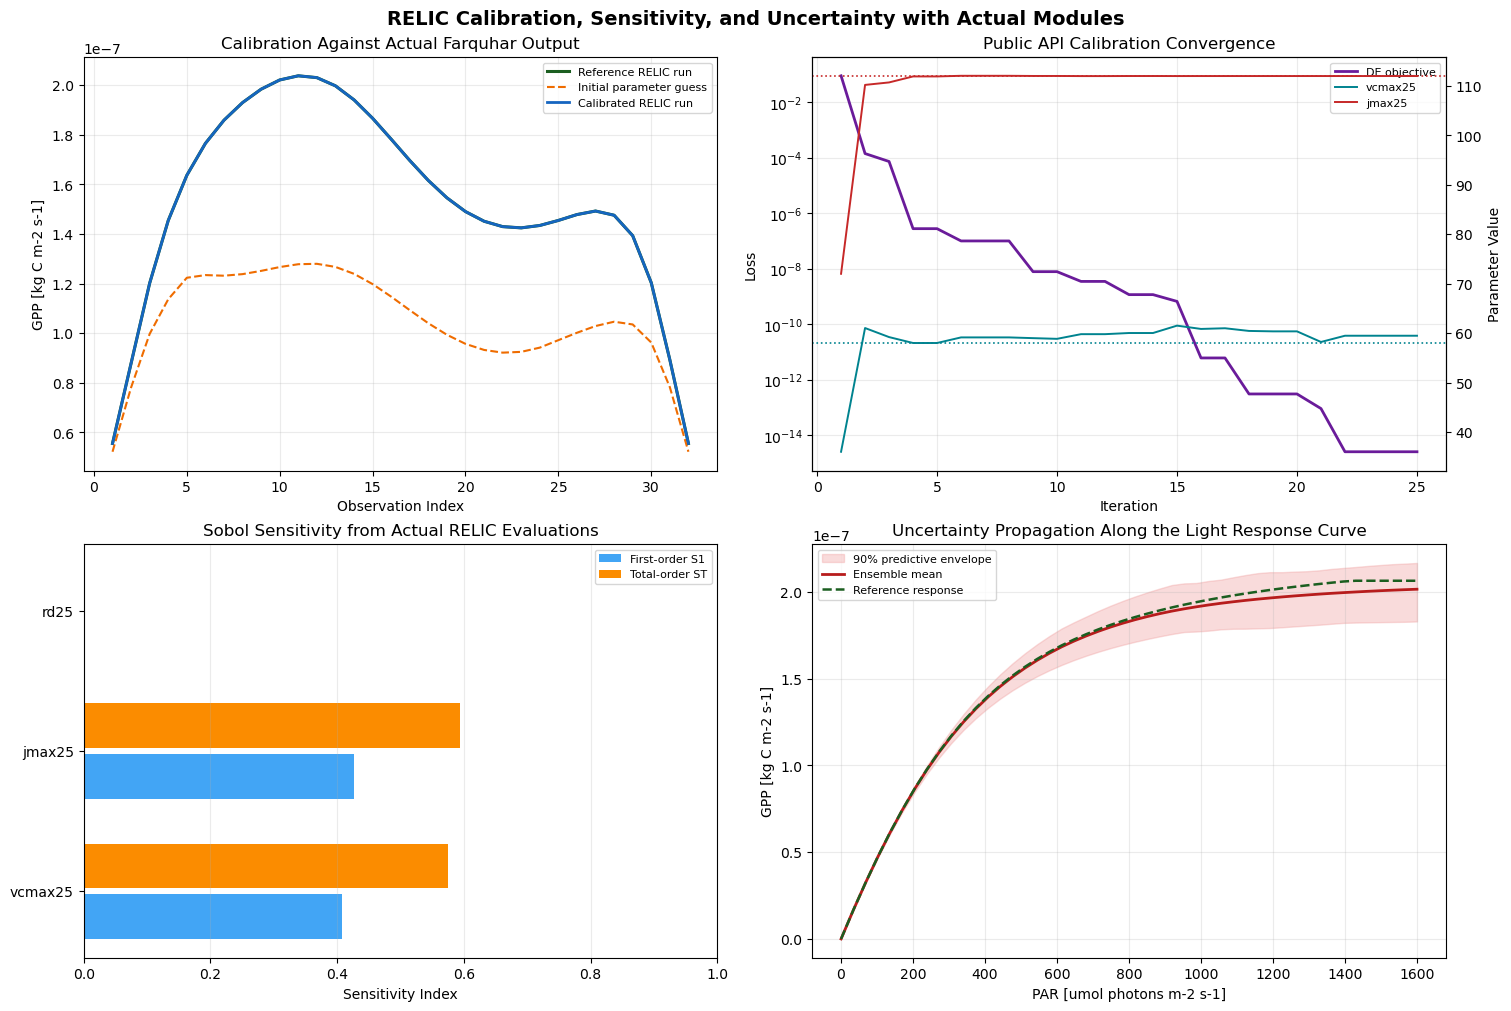

[OK] NB20 figures generated from actual RELIC calibration, Sobol, and ensemble outputs.


In [6]:
# ---------------------------------------------------------------
# References:
#   Farquhar et al. (1980), Planta -- photosynthetic light response through biochemical limitation
#   Sobol (2001), Math. Comput. Simul. -- sensitivity ranking visualization
#   Smith (2014), Uncertainty Quantification -- ensemble confidence envelopes
# Mathematical expression:
#   RMSE = sqrt(mean((y_hat - y_ref)^2))
#   response_band = [q_0.05(GPP), q_0.95(GPP)]
# Parameter meanings:
#   loss_history: calibration objective across optimizer steps
#   response_low/high: ensemble predictive envelope from actual RELIC members
# ---------------------------------------------------------------

import matplotlib.pyplot as plt

fig, axes = plt.subplots(2, 2, figsize=(15, 10), constrained_layout=True)
observation_index = list(range(1, observation_count + 1))

# Panel 1: Calibration fit on the actual observation sequence.
ax = axes[0, 0]
ax.plot(observation_index, gpp_reference.tolist(), color='#1b5e20', linewidth=2.2, label='Reference RELIC run')
ax.plot(observation_index, initial_gpp.tolist(), color='#ef6c00', linewidth=1.5, linestyle='--', label='Initial parameter guess')
ax.plot(observation_index, calibrated_gpp.tolist(), color='#1565c0', linewidth=2.0, label='Calibrated RELIC run')
ax.set_title('Calibration Against Actual Farquhar Output')
ax.set_xlabel('Observation Index')
ax.set_ylabel('GPP [kg C m-2 s-1]')
ax.grid(True, alpha=0.25)
ax.legend(fontsize=8)

# Panel 2: Convergence history from the public calibration API.
ax = axes[0, 1]
iteration_index = list(range(1, len(loss_history) + 1))
ax.plot(iteration_index, loss_history, color='#6a1b9a', linewidth=2.0, label='DE objective')
ax.set_title('Public API Calibration Convergence')
ax.set_xlabel('Iteration')
ax.set_ylabel('Loss')
ax.set_yscale('log')
ax.grid(True, alpha=0.25)
ax2 = ax.twinx()
ax2.plot(iteration_index, vcmax_history, color='#00838f', linewidth=1.4, label='vcmax25')
ax2.plot(iteration_index, jmax_history, color='#c62828', linewidth=1.4, label='jmax25')
ax2.axhline(reference_params['vcmax25'], color='#00838f', linestyle=':', linewidth=1.2)
ax2.axhline(reference_params['jmax25'], color='#c62828', linestyle=':', linewidth=1.2)
ax2.set_ylabel('Parameter Value')
line_group_1, label_group_1 = ax.get_legend_handles_labels()
line_group_2, label_group_2 = ax2.get_legend_handles_labels()
ax.legend(line_group_1 + line_group_2, label_group_1 + label_group_2, fontsize=8, loc='upper right')

# Panel 3: Actual Sobol indices for gpp_mean.
ax = axes[1, 0]
y_positions = list(range(len(sobol_parameter_labels)))
sobol_axis_max = max(1.0, max(sobol_first_order_values + sobol_total_order_values) * 1.15)
ax.barh([y - 0.18 for y in y_positions], sobol_first_order_values, height=0.32, color='#42a5f5', label='First-order S1')
ax.barh([y + 0.18 for y in y_positions], sobol_total_order_values, height=0.32, color='#fb8c00', label='Total-order ST')
ax.set_yticks(y_positions)
ax.set_yticklabels(sobol_parameter_labels)
sobol_axis_min = min(0.0, min(sobol_first_order_values + sobol_total_order_values) * 1.15)
ax.set_xlim(sobol_axis_min, sobol_axis_max)
ax.set_xlabel('Sensitivity Index')
ax.set_title('Sobol Sensitivity from Actual RELIC Evaluations')
ax.grid(True, alpha=0.25, axis='x')
ax.legend(fontsize=8)

# Panel 4: Uncertainty envelope from actual ensemble propagation.
ax = axes[1, 1]
ax.fill_between(
    par_response.tolist(),
    response_low.tolist(),
    response_high.tolist(),
    color='#ef9a9a',
    alpha=0.35,
    label='90% predictive envelope',
)
ax.plot(par_response.tolist(), response_mean.tolist(), color='#b71c1c', linewidth=2.0, label='Ensemble mean')
ax.plot(par_response.tolist(), reference_response.tolist(), color='#1b5e20', linewidth=1.8, linestyle='--', label='Reference response')
ax.set_title('Uncertainty Propagation Along the Light Response Curve')
ax.set_xlabel('PAR [umol photons m-2 s-1]')
ax.set_ylabel('GPP [kg C m-2 s-1]')
ax.grid(True, alpha=0.25)
ax.legend(fontsize=8)

fig.suptitle('RELIC Calibration, Sensitivity, and Uncertainty with Actual Modules', fontsize=14, fontweight='bold')
plt.show()
print('[OK] NB20 figures generated from actual RELIC calibration, Sobol, and ensemble outputs.')

## Summary

| Workflow | Actual RELIC path used in this notebook | Result |
|---|---|---|
| Calibration | `FarquharPhotosynthesis` + `ParameterCalibrator.calibrate(...)` | Twin-experiment parameter recovery from actual functor output |
| Sensitivity | `SobolAnalyzer.analyze(...)` | Variance-based ranking of `vcmax25`, `jmax25`, and `rd25` without notebook-side index clipping |
| Uncertainty | `EnsembleUQ.quantify(...)` + actual response reruns | Predictive envelope from sampled RELIC parameter sets |

This notebook now uses actual RELIC components end to end.
There is no notebook-defined pseudo-photosynthesis equation, pseudo-optimizer trace, or clipped sensitivity result driving the figures.

**Next**: NB21 Developer Guide for extending RELIC.